# GHAgentCI 2: adoption over time

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/unlv-evol/cai-miner/blob/main/notebooks/02-adoption-over-time.ipynb)

When do repositories start invoking coding agents from their CI, which agents do they adopt, does adoption differ by programming language, and do repositories keep their agentic workflows? This notebook answers these questions with the `revisions`, `steps` and `repositories` tables and the sampling frame.

**Dataset:** GHAgentCI, [https://doi.org/10.5281/zenodo.24088832](https://doi.org/10.5281/zenodo.24088832). **Field-by-field documentation:** [docs/DATASET.md](https://github.com/unlv-evol/cai-miner/blob/main/docs/DATASET.md).

The first code cell downloads each file from Zenodo once and caches it in a local folder (`ghagentci-data`, or the folder named by the `GHAGENTCI_DATA` environment variable).

In [1]:
import os
import urllib.request
from pathlib import Path

RECORD = "https://zenodo.org/records/24088832/files"
DATA = Path(os.environ.get("GHAGENTCI_DATA", "ghagentci-data"))


def fetch(name):
    path = DATA / name
    if not path.exists():
        DATA.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{RECORD}/{name}?download=1", path)
    return path

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# One small palette for every chart in these notebooks.
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#4a3aa7",
    "#e34948",
)
GREY = "#8a8985"
plt.rcParams.update(
    {
        "figure.figsize": (8, 4),
        "figure.dpi": 100,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.axisbelow": True,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.prop_cycle": plt.cycler(
            color=[BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED]
        ),
    }
)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

In [3]:
repos = pd.read_csv(fetch("repositories.csv.gz"), low_memory=False)
revisions = pd.read_csv(fetch("revisions.csv.gz"), low_memory=False)
steps = pd.read_csv(fetch("steps.csv.gz"), low_memory=False)
frame = pd.read_csv(fetch("frame-2026-10-03.csv.gz"), low_memory=False)
revisions["commit_date"] = pd.to_datetime(revisions["commit_date"], utc=True)
steps["commit_date"] = pd.to_datetime(steps["commit_date"], utc=True)

mined = repos[repos["status"].isin(["ok", "incomplete"])]
print(f"{len(mined):,} mined repositories")

196,253 mined repositories


## First agentic date per repository

A repository adopts agentic CI at its first agentic revision. The `repositories` table already stores
this as `first_agentic_date`; recomputing it from `revisions` gives the same answer.

In [4]:
first = (
    revisions[revisions["agentic"]]
    .groupby("repository")["commit_date"]
    .min()
    .rename("first_agentic")
)
stored = pd.to_datetime(repos.set_index("repository")["first_agentic_date"], utc=True).dropna()
print(
    f"{len(first):,} agentic repositories; "
    f"identical to repositories.first_agentic_date: "
    f"{len(stored) == len(first) and (stored.reindex(first.index) == first).all()}"
)
print("earliest adoption:", first.min().date(), "  latest:", first.max().date())

6,345 agentic repositories; identical to repositories.first_agentic_date: True
earliest adoption: 2023-07-16   latest: 2026-10-04


## New adopters per month

Monthly counts of repositories reaching their first agentic revision. The last month is partial
(mining ended in early October 2026), so it is drawn lighter.

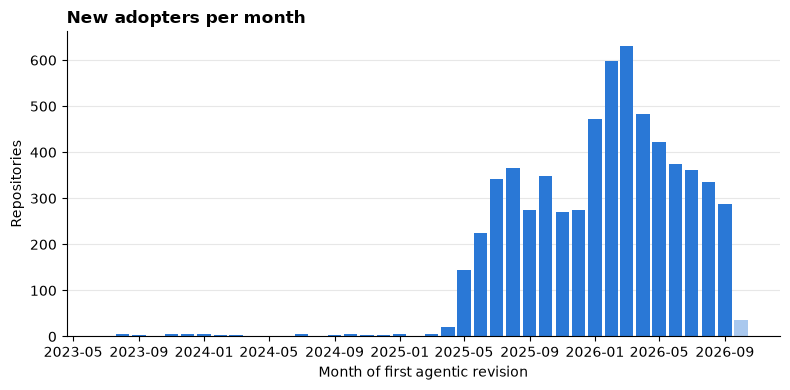

,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
new adopters,270,275,472,598,631,483,422,375,362,335,288,36


In [5]:
month = first.dt.tz_localize(None).dt.to_period("M")
monthly = month.value_counts().sort_index()
monthly = monthly.reindex(
    pd.period_range(monthly.index.min(), monthly.index.max(), freq="M"), fill_value=0
)

fig, ax = plt.subplots()
colors = [BLUE] * (len(monthly) - 1) + ["#a9c8ee"]
ax.bar(monthly.index.to_timestamp(), monthly.values, width=25, color=colors)
ax.set_xlabel("Month of first agentic revision")
ax.set_ylabel("Repositories")
ax.set_title("New adopters per month")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
monthly.tail(12).to_frame("new adopters").T

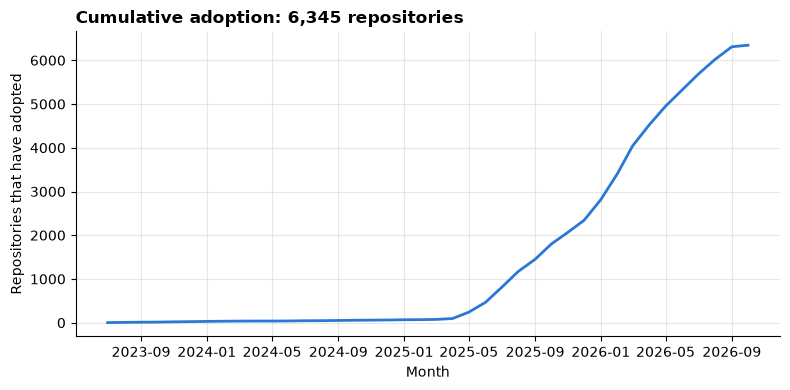

In [6]:
cumulative = monthly.cumsum()
fig, ax = plt.subplots()
ax.plot(cumulative.index.to_timestamp(), cumulative.values, color=BLUE, lw=2)
ax.set_xlabel("Month")
ax.set_ylabel("Repositories that have adopted")
ax.set_title(f"Cumulative adoption: {cumulative.iloc[-1]:,} repositories")
plt.tight_layout()
plt.show()

## Adoption per agent

For each agent, the first month a repository invokes it with strong evidence (`uses`, `run`,
`path`, `ghaw`). A repository that tries two agents counts once for each. `unknown` gh-aw engines
are left out here.

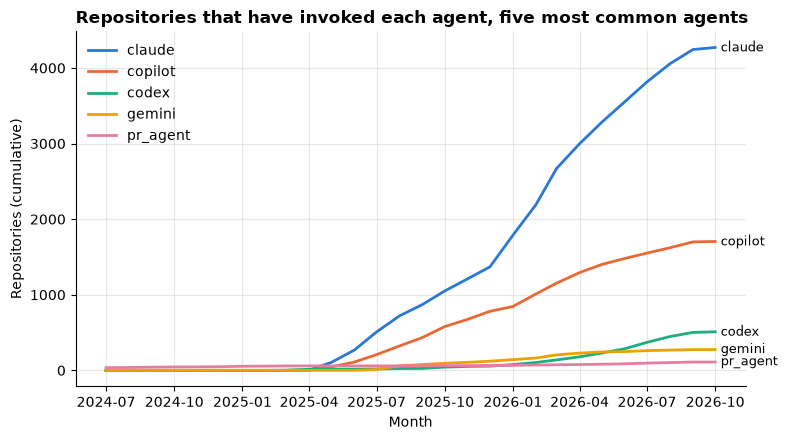

agent,claude,copilot,codex,gemini,pr_agent
repositories,4271,1705,510,275,110


In [7]:
STRONG = ["uses", "run", "path", "ghaw"]
strong = steps[steps["evidence_kind"].isin(STRONG) & (steps["agent"] != "unknown")]
first_by_agent = strong.groupby(["agent", "repository"])["commit_date"].min().reset_index()
first_by_agent["month"] = first_by_agent["commit_date"].dt.tz_localize(None).dt.to_period("M")

agents = first_by_agent["agent"].value_counts().head(5).index.tolist()
months = pd.period_range("2023-01", first_by_agent["month"].max(), freq="M")
curves = (
    first_by_agent[first_by_agent["agent"].isin(agents)]
    .groupby(["month", "agent"])
    .size()
    .unstack(fill_value=0)
    .reindex(months, fill_value=0)
    .cumsum()[agents]
)
curves = curves.loc["2024-07":]  # earlier months are flat near zero

fig, ax = plt.subplots(figsize=(8, 4.5))
for agent in agents:
    ax.plot(curves.index.to_timestamp(), curves[agent], lw=2, label=agent)
    ax.annotate(
        agent,
        (curves.index[-1].to_timestamp(), curves[agent].iloc[-1]),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
    )
ax.set_xlabel("Month")
ax.set_ylabel("Repositories (cumulative)")
ax.set_title("Repositories that have invoked each agent, five most common agents")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()
curves.iloc[-1].to_frame("repositories").T

## Adoption rate by main language

Join the mined repositories with the frame's `mainLanguage`, and compute the share that ever ran an
agentic workflow. Only languages with at least 1,000 mined repositories are shown; the dashed line
is the rate over all mined repositories.

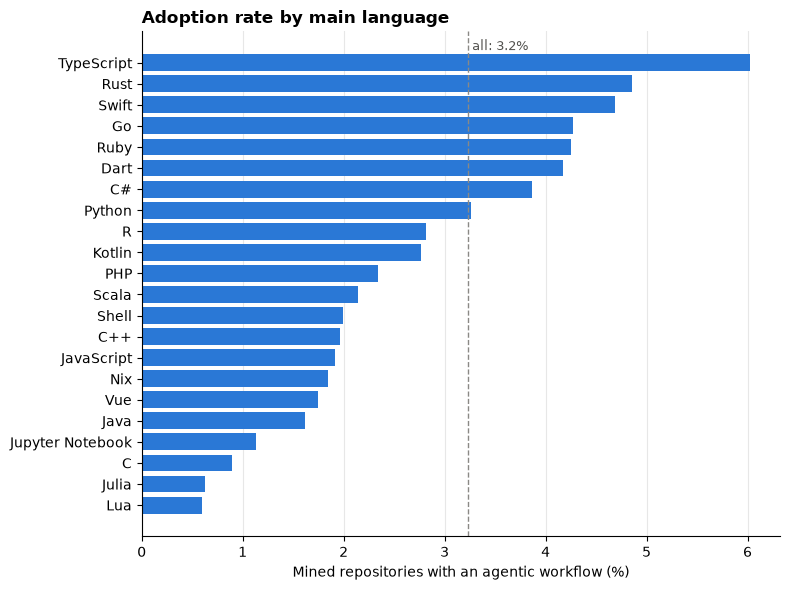

,mined,agentic,rate
mainLanguage,,,
TypeScript,"29,649","1,785",6.02%
Rust,"12,020",584,4.86%
Swift,"2,155",101,4.69%
Go,"12,207",522,4.28%
Ruby,"3,432",146,4.25%
Dart,"1,749",73,4.17%
C#,"8,045",311,3.87%
Python,"37,243","1,214",3.26%
R,"2,554",72,2.82%


In [8]:
lang = mined[["repository"]].merge(
    frame[["name", "mainLanguage"]], left_on="repository", right_on="name", how="left"
)
lang["agentic"] = lang["repository"].isin(first.index)
by_lang = lang.groupby("mainLanguage")["agentic"].agg(mined="size", agentic="sum")
by_lang["rate"] = by_lang["agentic"] / by_lang["mined"]
by_lang = by_lang[by_lang["mined"] >= 1000].sort_values("rate")
overall = lang["agentic"].mean()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(by_lang.index, 100 * by_lang["rate"], color=BLUE)
ax.axvline(100 * overall, color=GREY, ls="--", lw=1)
ax.text(100 * overall, len(by_lang) - 0.4, f" all: {overall:.1%}", color="#52514e", fontsize=9)
ax.set_xlabel("Mined repositories with an agentic workflow (%)")
ax.set_title("Adoption rate by main language")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
by_lang.sort_values("rate", ascending=False).style.format(
    {"rate": "{:.2%}", "mined": "{:,}", "agentic": "{:,}"}
)

## Do repositories keep their agents?

Take the **latest snapshot**: the last revision of each file history, leaving out histories whose
last revision deletes the file. A repository still invokes an agent if at least one of its latest
revisions is agentic.

Ordering matters: several revisions can share the same commit instant. The tables list each
history newest first, as `git log` does, so among equal timestamps the row further down is older.
We use the row position as a tie-breaker; sorting on the date alone would pick the wrong revision for
a handful of histories.

In [9]:
revisions["position"] = np.arange(len(revisions))
ordered = revisions.sort_values(["commit_date", "position"], ascending=[True, False])
latest = ordered.groupby(["repository", "uid"]).tail(1)
latest = latest[latest["git_change_type"] != "Deleted"]

still = set(latest.loc[latest["agentic"], "repository"])
stopped = set(first.index) - still
print(
    f"{len(latest):,} workflow files exist at the snapshot; {latest['agentic'].sum():,} of them are agentic"
)
print(f"{len(still):,} repositories still invoke an agent (paper: 4,598)")
print(f"{len(stopped):,} repositories stopped ({len(stopped) / len(first):.1%} of adopters)")

9,942 workflow files exist at the snapshot; 9,265 of them are agentic
4,598 repositories still invoke an agent (paper: 4,598)
1,747 repositories stopped (27.5% of adopters)


Older adopters have had more time to stop, so the share still agentic is shown per adoption
quarter rather than as a single figure. Recent quarters will look healthier partly for that reason.

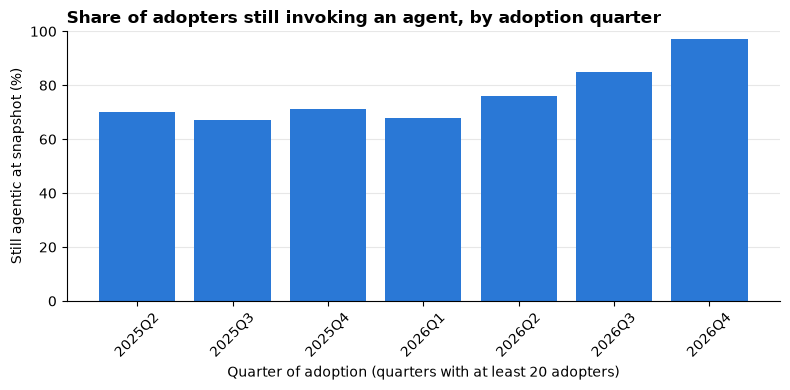

quarter,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3,2026Q4
adopters,391,983,894,1701,1280,985,36
share,70%,67%,71%,68%,76%,85%,97%


In [10]:
cohort = pd.DataFrame(
    {"quarter": first.dt.tz_localize(None).dt.to_period("Q"), "still": first.index.isin(still)},
    index=first.index,
)
by_q = cohort.groupby("quarter")["still"].agg(adopters="size", share="mean")
by_q = by_q[by_q["adopters"] >= 20]

fig, ax = plt.subplots()
ax.bar(by_q.index.astype(str), 100 * by_q["share"], color=BLUE)
ax.set_ylim(0, 100)
ax.set_xlabel("Quarter of adoption (quarters with at least 20 adopters)")
ax.set_ylabel("Still agentic at snapshot (%)")
ax.set_title("Share of adopters still invoking an agent, by adoption quarter")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
by_q.assign(share=by_q["share"].map("{:.0%}".format)).T

Notes: a repository counts as stopped only when *none* of its workflow files invokes an agent
any more, so replacing one agentic workflow by another is not a stop. The data cannot tell whether
the agent moved somewhere outside GitHub Actions.

Next: [03-triggers-and-safeguards](03-triggers-and-safeguards.ipynb).